# 03 — Feature Engineering and Feature Selection

## Task 1: binary classification — synthetic Alzheimer dataset

This notebook continues the tabular workflow after preprocessing and exploratory data analysis. Its purpose is to show how to **construct candidate features**, inspect redundancy, and perform **leakage-safe feature selection** for a binary classification task.

The notebook does **not** attempt to identify a final predictive model. Instead, it prepares and documents alternative feature spaces that can later be compared under the same modelling and validation protocol.

## Learning objectives

After completing this notebook, students should be able to:

- distinguish feature engineering from feature selection;
- create interpretable derived variables from existing predictors;
- understand which operations can be performed without using the target;
- split the data **before supervised feature selection**;
- identify constant, near-constant, and strongly redundant predictors;
- apply type-aware filter methods for numerical and categorical predictors;
- use mutual information as a nonlinear screening method;
- use L1-regularized logistic regression as an embedded selector;
- compare several selection criteria instead of treating one ranking as ground truth;
- export an engineered dataset and a transparent feature-selection manifest.

## 1. Leakage rule

Feature engineering and selection are often where data leakage enters a workflow.

In this notebook we separate two situations:

**Target-independent engineering**

```text
blood pressures -> pulse pressure
waist and height -> waist-to-height ratio
binary risk indicators -> burden count
```

These formulas do not use the target and can be applied deterministically to new observations.

**Target-dependent selection**

```text
statistical association with Alzheimer label
mutual information
L1 coefficient selection
```

These operations must be learned using the **training partition only**. The held-out test partition is not used to choose features.

## 2. Imports and reproducibility

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.multitest import multipletests

from sklearn.feature_selection import mutual_info_classif, mutual_info_regression
from sklearn.linear_model import LogisticRegression, ElasticNetCV
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    KFold,
    GridSearchCV,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")
PASTEL_SEQUENTIAL_CMAP = sns.light_palette("#5B8DB8", as_cmap=True)
PASTEL_DIVERGING_CMAP = sns.diverging_palette(275, 145, s=45, l=75, center="light", as_cmap=True)

## 3. Project paths

In [2]:
def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate the repository root. Run the notebook from inside the project."
    )

PROJECT_ROOT = find_project_root(Path.cwd())

PROCESSED_DIR = PROJECT_ROOT / "data" / "synthetic_alzheimer" / "processed_data"
PROCESSED_DATA_PATH = PROCESSED_DIR / "synthetic_alzheimer_patients_1000_processed.csv"
PREPROCESSING_REPORT_PATH = PROCESSED_DIR / "preprocessing_report.json"

FEATURE_DATA_DIR = PROJECT_ROOT / "data" / "synthetic_alzheimer" / "feature_data"
RESULTS_DIR = PROJECT_ROOT / "results" / "synthetic_alzheimer" / "feature_engineering_selection"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"

for directory in [FEATURE_DATA_DIR, FIGURES_DIR, TABLES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Results:", RESULTS_DIR.relative_to(PROJECT_ROOT))

Project root: /home/david/Desktop/depto_computacion/ml_2026/demos_machine_learning_2026
Results: results/synthetic_alzheimer/feature_engineering_selection


## 4. Load the processed dataset and analytical roles

We start from the output of the preprocessing notebook. The preprocessing report is reused so that column roles remain consistent across the workflow.

In [3]:
if not PROCESSED_DATA_PATH.exists() or not PREPROCESSING_REPORT_PATH.exists():
    raise FileNotFoundError(
        "Processed data are missing. Run task1_alzheimer/01_tabular_data_preprocessing.ipynb first."
    )

df = pd.read_csv(PROCESSED_DATA_PATH)
with PREPROCESSING_REPORT_PATH.open("r", encoding="utf-8") as file:
    preprocessing_report = json.load(file)

ID_COLUMN = preprocessing_report["identifier_column"]
TARGET_COLUMN = preprocessing_report["target_column"]
ORIGINAL_NUMERICAL = list(preprocessing_report["numerical_columns"])
CATEGORICAL_COLUMNS = list(preprocessing_report["categorical_columns"])

role_summary = pd.DataFrame({
    "role": ["identifier", "numerical predictors", "categorical predictors", "target"],
    "count": [1, len(ORIGINAL_NUMERICAL), len(CATEGORICAL_COLUMNS), 1],
})

display(role_summary)
print("Shape:", df.shape)
print("Target counts:")
display(df[TARGET_COLUMN].value_counts().rename_axis("label").to_frame("n"))

,role,count
0,identifier,1
1,numerical predictors,10
2,categorical predictors,19
3,target,1


Shape: (1000, 31)
Target counts:


,n
label,
0,657
1,343


## 5. Create the held-out partition before supervised selection

The split is stratified because this is a binary classification task. The test set is reserved for later model evaluation. We may transform it using formulas learned without the target, but we do not inspect target associations in it during feature selection.

In [4]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df[TARGET_COLUMN],
    random_state=RANDOM_STATE,
)

split_summary = pd.DataFrame({
    "partition": ["train", "test"],
    "n": [len(train_df), len(test_df)],
    "positive_fraction": [train_df[TARGET_COLUMN].mean(), test_df[TARGET_COLUMN].mean()],
})
display(split_summary.round(3))

split_assignments = pd.concat([
    train_df[[ID_COLUMN]].assign(split="train"),
    test_df[[ID_COLUMN]].assign(split="test"),
], ignore_index=True)
split_assignments.to_csv(TABLES_DIR / "train_test_split.csv", index=False)

,partition,n,positive_fraction
0,train,800,0.342
1,test,200,0.345


# Part I — Feature engineering

## 6. Define deterministic, interpretable features

The dataset already contains BMI and waist-to-hip ratio, so we do not recreate them. Instead, we add a small number of interpretable variables that summarize complementary physiological information.

The formulas below use predictor values only. They do not use the Alzheimer label.

In [5]:
def engineer_alzheimer_features(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()

    out["pulse_pressure_mmhg"] = out["systolic_bp_mmhg"] - out["diastolic_bp_mmhg"]
    out["mean_arterial_pressure_mmhg"] = (
        out["systolic_bp_mmhg"] + 2 * out["diastolic_bp_mmhg"]
    ) / 3
    out["waist_height_ratio"] = out["waist_cm"] / out["height_cm"]

    cardiometabolic = [
        "hypertension",
        "diabetes_type2",
        "dyslipidemia",
        "cardiovascular_disease",
        "stroke_history",
    ]
    neurobehavioral = [
        "depression_history",
        "traumatic_brain_injury",
        "sleep_disorder",
        "hearing_loss",
    ]

    out["cardiometabolic_risk_count"] = out[cardiometabolic].sum(axis=1)
    out["neurobehavioral_risk_count"] = out[neurobehavioral].sum(axis=1)

    return out


train_eng = engineer_alzheimer_features(train_df)
test_eng = engineer_alzheimer_features(test_df)
full_eng = engineer_alzheimer_features(df)

ENGINEERED_NUMERICAL = [
    "pulse_pressure_mmhg",
    "mean_arterial_pressure_mmhg",
    "waist_height_ratio",
    "cardiometabolic_risk_count",
    "neurobehavioral_risk_count",
]
NUMERICAL_COLUMNS = ORIGINAL_NUMERICAL + ENGINEERED_NUMERICAL
FEATURE_COLUMNS = NUMERICAL_COLUMNS + CATEGORICAL_COLUMNS

assert set(FEATURE_COLUMNS).issubset(train_eng.columns)
assert train_eng[FEATURE_COLUMNS].isna().sum().sum() == 0
assert test_eng[FEATURE_COLUMNS].isna().sum().sum() == 0

engineering_table = pd.DataFrame({
    "engineered_feature": ENGINEERED_NUMERICAL,
    "interpretation": [
        "Systolic minus diastolic blood pressure",
        "Approximate mean arterial pressure",
        "Waist circumference normalized by height",
        "Count of five cardiometabolic/vascular risk indicators",
        "Count of four neurological/behavioral risk indicators",
    ],
})
display(engineering_table)

,engineered_feature,interpretation
0,pulse_pressure_mmhg,Systolic minus diastolic blood pressure
1,mean_arterial_pressure_mmhg,Approximate mean arterial pressure
2,waist_height_ratio,Waist circumference normalized by height
3,cardiometabolic_risk_count,Count of five cardiometabolic/vascular risk in...
4,neurobehavioral_risk_count,Count of four neurological/behavioral risk ind...


## 7. Export the engineered candidate dataset

The engineered dataset is an **input candidate space**, not a final selected matrix. It contains all original predictors plus the deterministic engineered features.

Keeping engineering and selection separate is useful because future modelling notebooks can compare alternative selection strategies without rebuilding the variables.

In [6]:
ENGINEERED_DATA_PATH = FEATURE_DATA_DIR / "synthetic_alzheimer_engineered.csv"
full_eng.to_csv(ENGINEERED_DATA_PATH, index=False)
print("Exported:", ENGINEERED_DATA_PATH.relative_to(PROJECT_ROOT))
print("Shape:", full_eng.shape)

Exported: data/synthetic_alzheimer/feature_data/synthetic_alzheimer_engineered.csv
Shape: (1000, 36)


# Part II — Unsupervised screening

## 8. Constant and near-constant predictors

A feature can be unsuitable even before considering the target. Here we inspect variance and prevalence using the training set only.

For binary variables, a prevalence below 1% or above 99% is flagged as near-constant. A flag is a reason to investigate, not an automatic deletion rule.

In [7]:
constant_numerical = [c for c in NUMERICAL_COLUMNS if train_eng[c].nunique(dropna=False) <= 1]

categorical_prevalence = train_eng[CATEGORICAL_COLUMNS].mean().rename("prevalence").to_frame()
categorical_prevalence["near_constant"] = (
    (categorical_prevalence["prevalence"] < 0.01)
    | (categorical_prevalence["prevalence"] > 0.99)
)

print("Constant numerical features:", constant_numerical or "None")
display(categorical_prevalence.sort_values("prevalence"))

Constant numerical features: None


,prevalence,near_constant
chronic_kidney_disease,0.06750,False
stroke_history,0.08875,False
traumatic_brain_injury,0.09250,False
allergy_food,0.10250,False
alcohol_risk,0.13000,False
smoker,0.15000,False
asthma,0.15125,False
cardiovascular_disease,0.15500,False
diabetes_type2,0.15625,False
allergy_medication,0.16375,False


In [8]:
def benjamini_hochberg(p_values):
    p_values = np.asarray(p_values, dtype=float)
    valid = np.isfinite(p_values)
    adjusted = np.full(len(p_values), np.nan, dtype=float)
    rejected = np.full(len(p_values), False, dtype=bool)
    if valid.any():
        rejected_valid, adjusted_valid, _, _ = multipletests(
            p_values[valid], alpha=0.05, method="fdr_bh"
        )
        adjusted[valid] = adjusted_valid
        rejected[valid] = rejected_valid
    return adjusted, rejected


def cramers_v(table):
    chi2, _, _, _ = stats.chi2_contingency(table, correction=False)
    n = table.to_numpy().sum()
    if n == 0:
        return np.nan
    r, k = table.shape
    denominator = min(k - 1, r - 1)
    if denominator <= 0:
        return 0.0
    return np.sqrt((chi2 / n) / denominator)


def hedges_g(x0, x1):
    x0 = np.asarray(x0, dtype=float)
    x1 = np.asarray(x1, dtype=float)
    x0 = x0[np.isfinite(x0)]
    x1 = x1[np.isfinite(x1)]
    n0, n1 = len(x0), len(x1)
    if n0 < 2 or n1 < 2:
        return np.nan
    pooled_var = ((n0 - 1) * x0.var(ddof=1) + (n1 - 1) * x1.var(ddof=1)) / (n0 + n1 - 2)
    if pooled_var <= 0:
        return 0.0
    d = (x1.mean() - x0.mean()) / np.sqrt(pooled_var)
    correction = 1 - 3 / (4 * (n0 + n1) - 9)
    return correction * d


def cliffs_delta_from_u(u_statistic, n0, n1):
    if n0 == 0 or n1 == 0:
        return np.nan
    return (2 * u_statistic) / (n0 * n1) - 1


def correlation_pairs(corr, threshold=0.90):
    rows = []
    columns = list(corr.columns)
    for i, left in enumerate(columns):
        for right in columns[i + 1:]:
            value = corr.loc[left, right]
            if np.isfinite(value) and abs(value) >= threshold:
                rows.append({
                    "feature_a": left,
                    "feature_b": right,
                    "spearman_rho": value,
                    "abs_spearman_rho": abs(value),
                })
    if not rows:
        return pd.DataFrame(columns=["feature_a", "feature_b", "spearman_rho", "abs_spearman_rho"])
    return pd.DataFrame(rows).sort_values("abs_spearman_rho", ascending=False).reset_index(drop=True)


def plot_horizontal_ranking(frame, value_col, label_col, title, xlabel, path, top_n=20):
    plot_df = frame.sort_values(value_col, ascending=False).head(top_n).copy()
    plt.figure(figsize=(9, max(4.5, 0.34 * len(plot_df))))
    sns.barplot(data=plot_df, y=label_col, x=value_col, color=sns.color_palette("pastel")[0])
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("")
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()

## 9. Numerical redundancy

Strong correlation does not prove that one variable should be removed, but it identifies potential redundancy. We use Spearman correlation because it captures monotonic association without assuming linearity.

Derived variables such as mean arterial pressure are expected to correlate strongly with the measurements from which they were constructed. This is useful pedagogically: feature engineering can **add information representations while also increasing redundancy**.

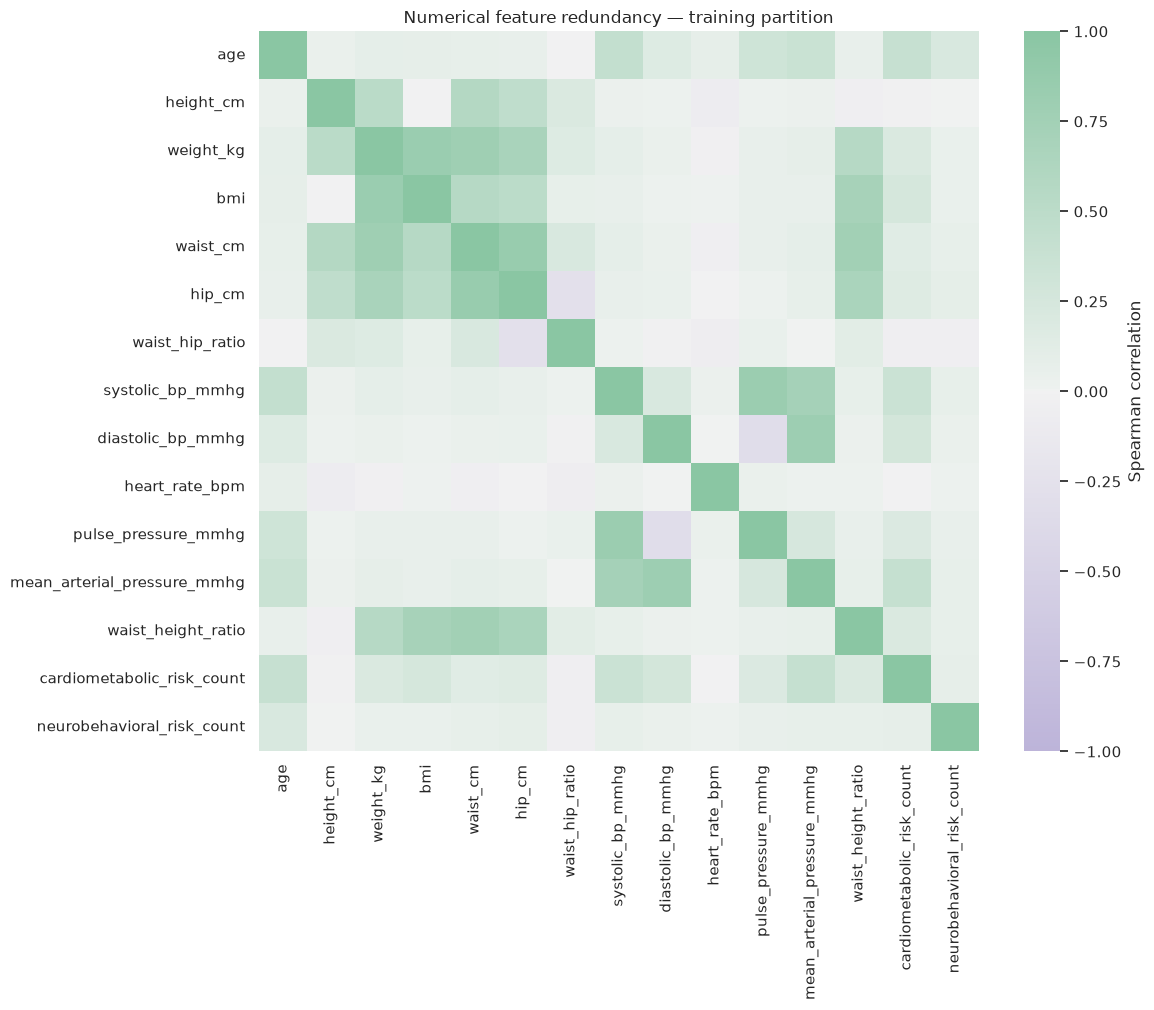

,feature_a,feature_b,spearman_rho,abs_spearman_rho


In [9]:
spearman_corr = train_eng[NUMERICAL_COLUMNS].corr(method="spearman")
redundant_pairs = correlation_pairs(spearman_corr, threshold=0.90)

plt.figure(figsize=(12, 10))
sns.heatmap(
    spearman_corr,
    cmap=PASTEL_DIVERGING_CMAP,
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    cbar_kws={"label": "Spearman correlation"},
)
plt.title("Numerical feature redundancy — training partition")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_numerical_redundancy_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

display(redundant_pairs.head(20))
redundant_pairs.to_csv(TABLES_DIR / "numerical_redundant_pairs.csv", index=False)

# Part III — Supervised filter methods

## 10. Numerical predictors versus a binary target

For numerical predictors we combine:

- Welch's t-test, which compares group means without assuming equal variance;
- Mann–Whitney U, a rank-based comparison;
- Cliff's delta, a nonparametric effect size;
- Benjamini–Hochberg FDR correction across features.

For an instructional filter candidate we require both statistical evidence after FDR correction and at least a small absolute Cliff's delta (`|δ| >= 0.147`). This threshold is illustrative, not universal.

,feature,mean_no_alzheimer,mean_alzheimer,welch_p,mann_whitney_p,cliffs_delta,abs_cliffs_delta,mann_whitney_q,fdr_reject,filter_selected
0,age,65.2947,75.1934,0.0000,0.0000,-0.5125,0.5125,0.0000,True,True
1,cardiometabolic_risk_count,0.7966,1.4562,0.0000,0.0000,-0.3530,0.3530,0.0000,True,True
2,systolic_bp_mmhg,128.0608,135.7117,0.0000,0.0000,-0.3153,0.3153,0.0000,True,True
3,mean_arterial_pressure_mmhg,95.4753,99.1010,0.0000,0.0000,-0.2546,0.2546,0.0000,True,True
4,pulse_pressure_mmhg,48.8783,54.9161,0.0000,0.0000,-0.2359,0.2359,0.0000,True,True
5,neurobehavioral_risk_count,0.5856,0.8905,0.0000,0.0000,-0.1985,0.1985,0.0000,True,True
6,diastolic_bp_mmhg,79.1825,80.7956,0.0117,0.0258,-0.0959,0.0959,0.0553,False,False
7,waist_hip_ratio,0.9278,0.9233,0.1184,0.0850,0.0741,0.0741,0.1594,False,False
8,height_cm,165.7260,164.9624,0.2238,0.1866,0.0569,0.0569,0.3110,False,False
9,bmi,26.8591,27.2511,0.2122,0.2479,-0.0497,0.0497,0.3719,False,False


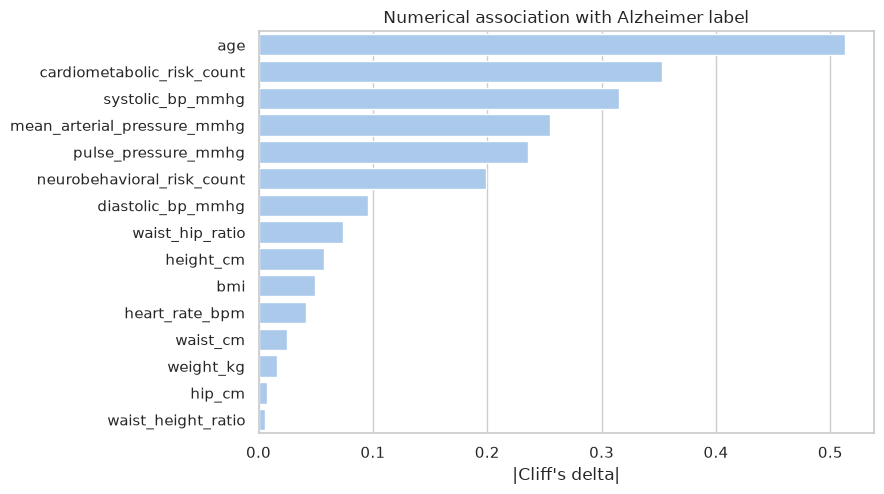

In [10]:
numerical_rows = []
for feature in NUMERICAL_COLUMNS:
    x0 = train_eng.loc[train_eng[TARGET_COLUMN] == 0, feature].dropna()
    x1 = train_eng.loc[train_eng[TARGET_COLUMN] == 1, feature].dropna()

    welch = stats.ttest_ind(x0, x1, equal_var=False, nan_policy="omit")
    mann = stats.mannwhitneyu(x0, x1, alternative="two-sided")
    delta = cliffs_delta_from_u(mann.statistic, len(x0), len(x1))

    numerical_rows.append({
        "feature": feature,
        "mean_no_alzheimer": x0.mean(),
        "mean_alzheimer": x1.mean(),
        "welch_p": welch.pvalue,
        "mann_whitney_p": mann.pvalue,
        "cliffs_delta": delta,
        "abs_cliffs_delta": abs(delta),
    })

numerical_filter = pd.DataFrame(numerical_rows)
numerical_filter["mann_whitney_q"], numerical_filter["fdr_reject"] = benjamini_hochberg(
    numerical_filter["mann_whitney_p"]
)
numerical_filter["filter_selected"] = (
    numerical_filter["fdr_reject"]
    & (numerical_filter["abs_cliffs_delta"] >= 0.147)
)
numerical_filter = numerical_filter.sort_values("abs_cliffs_delta", ascending=False).reset_index(drop=True)

display(numerical_filter.round(4))
numerical_filter.to_csv(TABLES_DIR / "numerical_filter_selection.csv", index=False)
plot_horizontal_ranking(
    numerical_filter,
    "abs_cliffs_delta",
    "feature",
    "Numerical association with Alzheimer label",
    "|Cliff's delta|",
    FIGURES_DIR / "02_numerical_filter_effect_sizes.png",
)

## 11. Binary categorical predictors versus the target

For each binary predictor we build a contingency table against the target. Chi-square is used when expected counts are adequate; Fisher's exact test is used as a fallback for sparse `2 × 2` tables.

Cramér's V summarizes effect magnitude on a common `0–1` scale. Again, the threshold used below (`V >= 0.10`) is an educational screening rule rather than a universal law.

,feature,test,p_value,cramers_v,q_value,fdr_reject,filter_selected
0,hypertension,Chi-square,0.0000,0.2415,0.0000,True,True
1,stroke_history,Chi-square,0.0000,0.2286,0.0000,True,True
2,family_history_alzheimer,Chi-square,0.0000,0.2263,0.0000,True,True
3,hearing_loss,Chi-square,0.0000,0.1993,0.0000,True,True
4,diabetes_type2,Chi-square,0.0000,0.1900,0.0000,True,True
5,physical_inactivity,Chi-square,0.0024,0.1075,0.0075,True,True
6,cardiovascular_disease,Chi-square,0.0028,0.1058,0.0075,True,True
7,chronic_kidney_disease,Chi-square,0.0048,0.0998,0.0113,True,False
8,allergy_food,Chi-square,0.0149,0.0861,0.0314,True,False
9,depression_history,Chi-square,0.0433,0.0715,0.0822,False,False


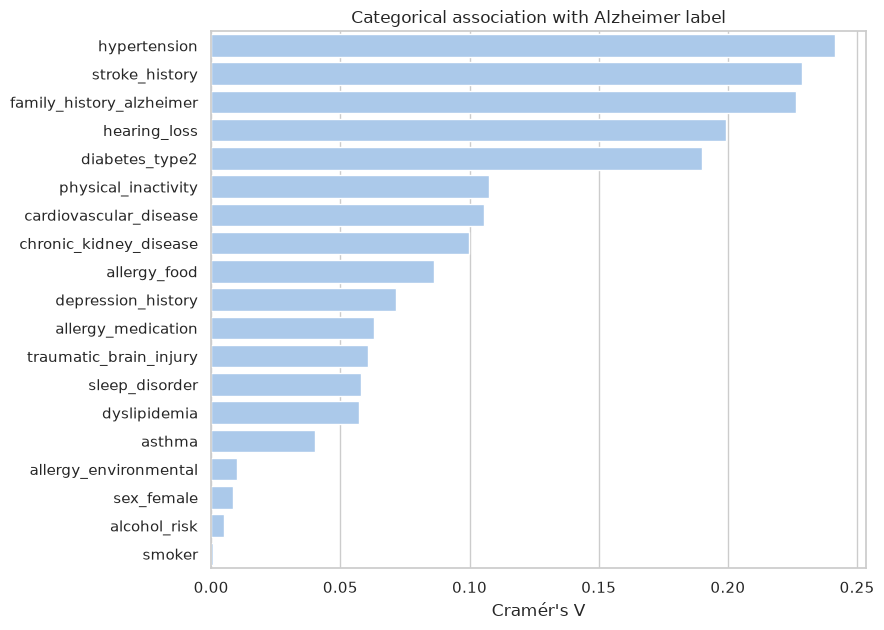

In [11]:
categorical_rows = []
for feature in CATEGORICAL_COLUMNS:
    table = pd.crosstab(train_eng[feature], train_eng[TARGET_COLUMN])
    chi2, chi_p, _, expected = stats.chi2_contingency(table, correction=False)
    use_fisher = table.shape == (2, 2) and (expected < 5).any()
    if use_fisher:
        _, p_value = stats.fisher_exact(table.to_numpy())
        test_name = "Fisher exact"
    else:
        p_value = chi_p
        test_name = "Chi-square"

    categorical_rows.append({
        "feature": feature,
        "test": test_name,
        "p_value": p_value,
        "cramers_v": cramers_v(table),
    })

categorical_filter = pd.DataFrame(categorical_rows)
categorical_filter["q_value"], categorical_filter["fdr_reject"] = benjamini_hochberg(
    categorical_filter["p_value"]
)
categorical_filter["filter_selected"] = (
    categorical_filter["fdr_reject"]
    & (categorical_filter["cramers_v"] >= 0.10)
)
categorical_filter = categorical_filter.sort_values("cramers_v", ascending=False).reset_index(drop=True)

display(categorical_filter.round(4))
categorical_filter.to_csv(TABLES_DIR / "categorical_filter_selection.csv", index=False)
plot_horizontal_ranking(
    categorical_filter,
    "cramers_v",
    "feature",
    "Categorical association with Alzheimer label",
    "Cramér's V",
    FIGURES_DIR / "03_categorical_filter_effect_sizes.png",
)

# Part IV — Mutual information

## 12. A nonlinear screening view

Mutual information can detect dependence that is not well described by a mean difference or a monotonic coefficient. It is still a supervised method, so it is estimated on the training partition only.

The numerical and binary predictors are supplied together, while the binary columns are marked as discrete.

,feature,mutual_information,top_quartile_positive_mi
0,age,0.0978,True
1,cardiometabolic_risk_count,0.0810,True
2,hypertension,0.0287,True
3,waist_hip_ratio,0.0283,True
4,mean_arterial_pressure_mmhg,0.0256,True
5,family_history_alzheimer,0.0247,True
6,stroke_history,0.0246,True
7,systolic_bp_mmhg,0.0232,True
8,hearing_loss,0.0189,False
9,diabetes_type2,0.0172,False


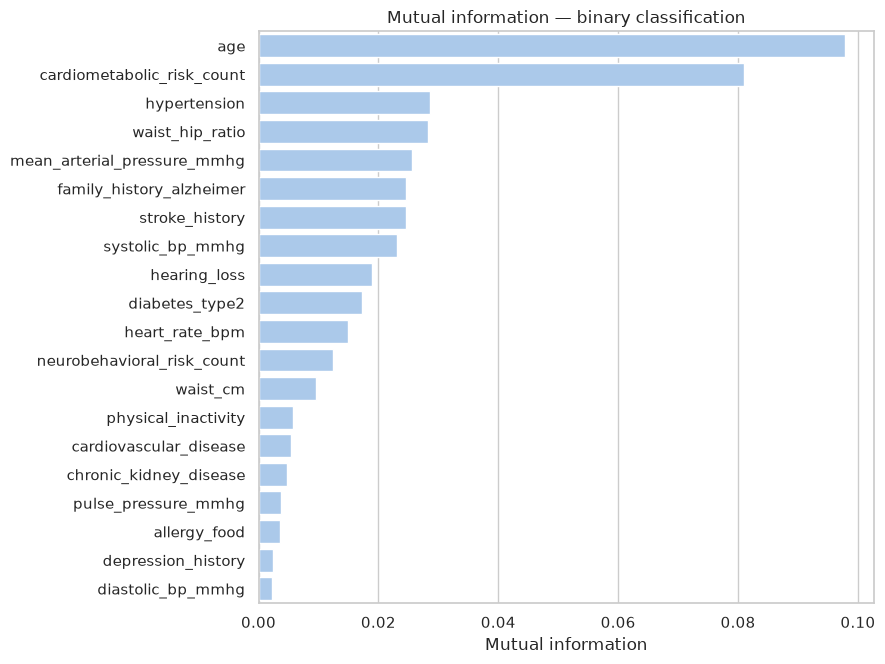

In [12]:
X_train = train_eng[FEATURE_COLUMNS]
y_train = train_eng[TARGET_COLUMN]

discrete_mask = np.array([feature in CATEGORICAL_COLUMNS for feature in FEATURE_COLUMNS])
mi_values = mutual_info_classif(
    X_train,
    y_train,
    discrete_features=discrete_mask,
    random_state=RANDOM_STATE,
)

mutual_information = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "mutual_information": mi_values,
}).sort_values("mutual_information", ascending=False).reset_index(drop=True)

positive_mi = mutual_information.loc[mutual_information["mutual_information"] > 0, "mutual_information"]
mi_threshold = positive_mi.quantile(0.75) if len(positive_mi) else np.inf
mutual_information["top_quartile_positive_mi"] = (
    mutual_information["mutual_information"] >= mi_threshold
)

display(mutual_information.round(4))
mutual_information.to_csv(TABLES_DIR / "mutual_information.csv", index=False)
plot_horizontal_ranking(
    mutual_information,
    "mutual_information",
    "feature",
    "Mutual information — binary classification",
    "Mutual information",
    FIGURES_DIR / "04_mutual_information.png",
)

# Part V — Embedded selection with L1 logistic regression

## 13. Why regularization can select features

L1 regularization encourages some coefficients to become exactly zero. We choose the regularization strength using cross-validation **inside the training partition**.

All predictors are standardized inside a `Pipeline`. The test set is not used by `GridSearchCV`.

Best C: 0.07196856730011521
Best training-CV ROC AUC: 0.791


,feature,coefficient,abs_coefficient,embedded_selected
0,age,0.7398,0.7398,True
1,family_history_alzheimer,0.3589,0.3589,True
2,diabetes_type2,0.1688,0.1688,True
3,stroke_history,0.1470,0.1470,True
4,neurobehavioral_risk_count,0.1168,0.1168,True
5,waist_cm,-0.0925,0.0925,True
6,cardiometabolic_risk_count,0.0890,0.0890,True
7,systolic_bp_mmhg,0.0890,0.0890,True
8,hypertension,0.0884,0.0884,True
9,hearing_loss,0.0613,0.0613,True


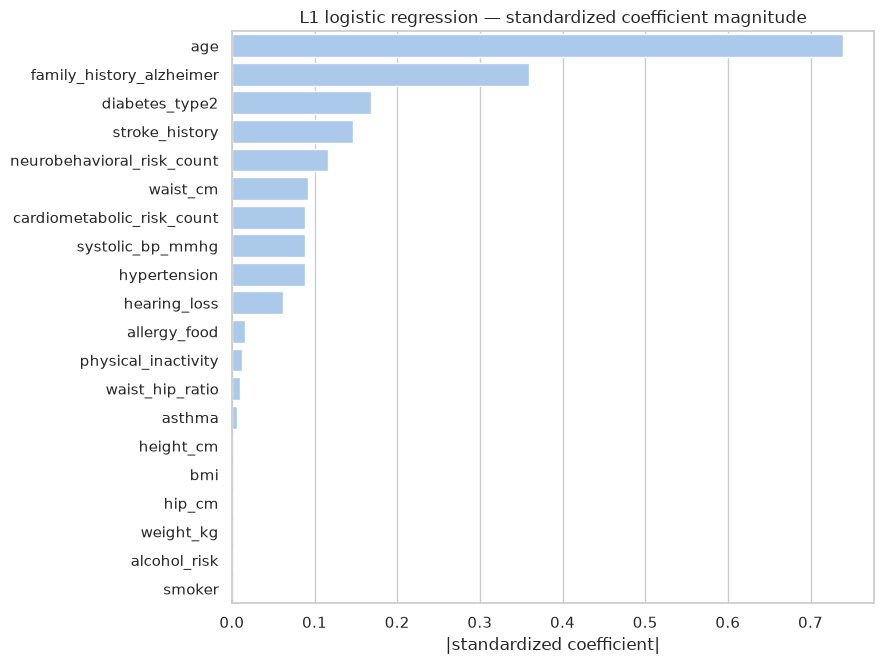

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

l1_pipeline = Pipeline([
    ("scale", StandardScaler()),
    (
        "model",
        LogisticRegression(
            solver="saga",
            l1_ratio=1.0,
            max_iter=5000,
            random_state=RANDOM_STATE,
        ),
    ),
])

l1_search = GridSearchCV(
    l1_pipeline,
    param_grid={"model__C": np.logspace(-2, 1, 8)},
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True,
)

l1_search.fit(X_train, y_train)
best_l1 = l1_search.best_estimator_
coefficients = best_l1.named_steps["model"].coef_.ravel()

l1_table = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "coefficient": coefficients,
    "abs_coefficient": np.abs(coefficients),
})
l1_table["embedded_selected"] = l1_table["abs_coefficient"] > 1e-8
l1_table = l1_table.sort_values("abs_coefficient", ascending=False).reset_index(drop=True)

print("Best C:", l1_search.best_params_["model__C"])
print("Best training-CV ROC AUC:", round(l1_search.best_score_, 3))
display(l1_table.round(4))
l1_table.to_csv(TABLES_DIR / "l1_logistic_coefficients.csv", index=False)
plot_horizontal_ranking(
    l1_table,
    "abs_coefficient",
    "feature",
    "L1 logistic regression — standardized coefficient magnitude",
    "|standardized coefficient|",
    FIGURES_DIR / "05_l1_coefficients.png",
)

# Part VI — Compare selection evidence

## 14. Do not treat one selector as ground truth

Different methods ask different questions. We therefore create a transparent vote table rather than declaring one ranking universally correct.

A feature receives one vote for each of:

1. passing the type-aware statistical filter;
2. being in the top quartile of positive mutual information;
3. receiving a nonzero L1 coefficient.

The **consensus candidate set** requires at least two votes. This is only a candidate set for future modelling; it still needs evaluation under cross-validation.

In [14]:
filter_selected = set(
    numerical_filter.loc[numerical_filter["filter_selected"], "feature"]
).union(
    categorical_filter.loc[categorical_filter["filter_selected"], "feature"]
)

mi_selected = set(
    mutual_information.loc[mutual_information["top_quartile_positive_mi"], "feature"]
)

embedded_selected = set(
    l1_table.loc[l1_table["embedded_selected"], "feature"]
)

selection_summary = pd.DataFrame({"feature": FEATURE_COLUMNS})
selection_summary["filter_selected"] = selection_summary["feature"].isin(filter_selected)
selection_summary["mi_top_quartile"] = selection_summary["feature"].isin(mi_selected)
selection_summary["l1_selected"] = selection_summary["feature"].isin(embedded_selected)
selection_summary["selection_votes"] = selection_summary[
    ["filter_selected", "mi_top_quartile", "l1_selected"]
].sum(axis=1)
selection_summary["consensus_selected"] = selection_summary["selection_votes"] >= 2
selection_summary = selection_summary.sort_values(
    ["selection_votes", "feature"], ascending=[False, True]
).reset_index(drop=True)

CONSENSUS_FEATURES = selection_summary.loc[
    selection_summary["consensus_selected"], "feature"
].tolist()

display(selection_summary)
print(f"All candidate predictors: {len(FEATURE_COLUMNS)}")
print(f"Consensus candidate predictors: {len(CONSENSUS_FEATURES)}")
print(CONSENSUS_FEATURES)
selection_summary.to_csv(TABLES_DIR / "feature_selection_summary.csv", index=False)

,feature,filter_selected,mi_top_quartile,l1_selected,selection_votes,consensus_selected
0,age,True,True,True,3,True
1,cardiometabolic_risk_count,True,True,True,3,True
2,family_history_alzheimer,True,True,True,3,True
3,hypertension,True,True,True,3,True
4,stroke_history,True,True,True,3,True
5,systolic_bp_mmhg,True,True,True,3,True
6,diabetes_type2,True,False,True,2,True
7,hearing_loss,True,False,True,2,True
8,mean_arterial_pressure_mmhg,True,True,False,2,True
9,neurobehavioral_risk_count,True,False,True,2,True


All candidate predictors: 34
Consensus candidate predictors: 12
['age', 'cardiometabolic_risk_count', 'family_history_alzheimer', 'hypertension', 'stroke_history', 'systolic_bp_mmhg', 'diabetes_type2', 'hearing_loss', 'mean_arterial_pressure_mmhg', 'neurobehavioral_risk_count', 'physical_inactivity', 'waist_hip_ratio']


## 15. Export the feature manifest

The manifest records the candidate feature spaces and the split used to learn supervised selection. A later modelling notebook should still refit supervised selection inside cross-validation when estimating generalization performance.

In [15]:
manifest = {
    "dataset": "synthetic_alzheimer",
    "task_type": "binary_classification",
    "random_state": RANDOM_STATE,
    "train_size": len(train_eng),
    "test_size": len(test_eng),
    "original_numerical_features": ORIGINAL_NUMERICAL,
    "engineered_numerical_features": ENGINEERED_NUMERICAL,
    "categorical_features": CATEGORICAL_COLUMNS,
    "all_candidate_features": FEATURE_COLUMNS,
    "filter_selected_features": sorted(filter_selected),
    "mutual_information_top_quartile_features": sorted(mi_selected),
    "l1_selected_features": sorted(embedded_selected),
    "consensus_features": CONSENSUS_FEATURES,
    "note": (
        "Supervised selection was learned on the training partition only. "
        "For formal model comparison, selection should be refit inside each training fold."
    ),
}

with (RESULTS_DIR / "feature_selection_manifest.json").open("w", encoding="utf-8") as file:
    json.dump(manifest, file, indent=2)

print("Feature manifest exported.")

Feature manifest exported.


# Final interpretation

This notebook illustrates a key principle: **feature selection is not a single command**.

For the binary task we combined:

```text
EDA-informed hypotheses
        ↓
deterministic feature engineering
        ↓
unsupervised quality/redundancy screening
        ↓
type-aware supervised filters on TRAIN
        ↓
mutual information on TRAIN
        ↓
L1 embedded selection with CV on TRAIN
        ↓
transparent candidate feature sets
```

The next modelling stage should compare the complete and reduced feature spaces using the same resampling strategy. A smaller feature set is useful only if it improves or preserves the properties we care about: generalization, stability, interpretability, and computational efficiency.